<div style="width: 100%; text-align: center; margin-bottom: 20px;">
  <img src="../elementos/cabecalho_branco.jpg" alt="Cabeçalho" style="max-width: 100%; height: auto;">
</div>

# O Andar do Bêbado

**Autor**: Carlos Gabriel de Oliveira Campos

**Professor**: Dr. Daniel Roberto Cassar

Um senhor acabou exagerando e tomou uma ou duas doses a mais do que deveria.
Esse senhor embriagado está andando por um campo plano, infinito e livre de obstáculos.
A cada minuto, ele dá um passo de exatamente 1 metro para norte, sul, leste ou oeste.
É sempre um passo por minuto e sempre um passo em apenas uma direção (todas as
direções têm a mesma probabilidade de serem escolhidas). Considere que o senhor andante inicia sua trajetória no tempo 𝑡 = 0 minutos na coordenada (0, 0).


---

## Imports e função de suporte

In [3]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

Para este trabalho, vamos criar uma função que simula o andar do bêbado, isto é, o movimento aleatório cujas possibilidades são equiprováveis. Desse modo, partido de (0, 0), quando o indivíduo dá um passo, a chance de que ele pare em (1, 0), (0, 1), (-1, 0) ou (0, -1) são todas iguais. Esta função retorna a posição final (x, y) dele, assim como duas listas em que são registradas as posições em x e em y (separadamente) em cada minuto $t$.

In [5]:
def simula_caminhada(num_passos=1,  mostra_resultado=False):

    valores_x = []
    valores_y = []

    posicao = {
        "x": 0,
        "y": 0
    }
    
    direcoes = ("x", "y")
    sentidos = (-1, 1)

    lista_direcoes = np.random.choice(direcoes, size=num_passos)
    lista_sentidos = np.random.choice(sentidos, size=num_passos)

    for direcao, sentido in zip(lista_direcoes, lista_sentidos):
        valores_x.append(posicao['x'])
        valores_y.append(posicao["y"])
        posicao[direcao] += sentido

    if mostra_resultado:
        print(f"POSIÇÃO FINAL:\nX: {posicao['x']}\nY: {posicao['y']}")

    return posicao, valores_x, valores_y

### Simulando um passo e uma caminhada

In [6]:
print("Simulando uma caminhada com um único passo")
simula_caminhada(mostra_resultado=True)

print("\nAgora com mil passos!")
simula_caminhada(1000, mostra_resultado=True);

Simulando uma caminhada com um único passo
POSIÇÃO FINAL:
X: 0
Y: -1

Agora com mil passos!
POSIÇÃO FINAL:
X: 57
Y: 19


Ou seja, mesmo com mil passos, podemos ver que o cidadão embriagado não vai muito longe (pode isso ser uma metáfora para a vida...?).

> ###  1. Faça um gráfico mostrando a trajetória do bêbado andante no plano.

Simulando uma caminhada com mil passos:

In [7]:
NUM_PASSOS = 1_000
_, valores_x, valores_y = simula_caminhada(NUM_PASSOS)

Apresentando o gráfico da trajetória, a cada 20 passos:

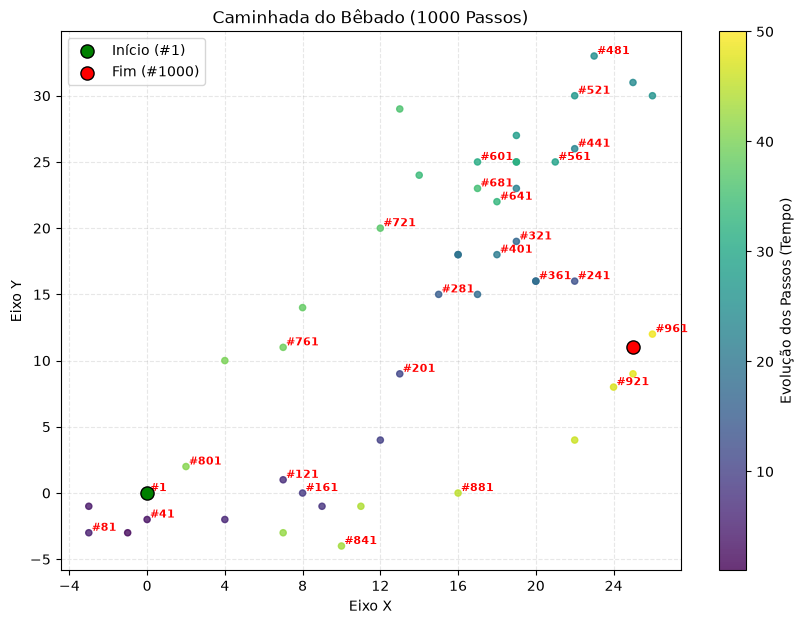

In [8]:
INTERVALO = 20
x_fracionado = valores_x[::INTERVALO]
y_fracionado = valores_y[::INTERVALO]

total_passos = len(x_fracionado)
passos = np.arange(1, total_passos + 1)

plt.figure(figsize=(10, 7))

# 1. Posições coloridas por gradiente de cor conforme a ordem do passo (Sem a linha plt.plot)
sc = plt.scatter(
    x_fracionado,
    y_fracionado,
    c=passos,
    cmap="viridis",
    s=20,
    alpha=0.8,
    zorder=2,
)
cbar = plt.colorbar(sc)
cbar.set_label("Evolução dos Passos (Tempo)")

# 2. Anota o número do passo apenas em intervalos (a cada 100 passos)
intervalo_rotulos = 2
for i in range(0, total_passos, intervalo_rotulos):
  plt.text(
      x_fracionado[i] + 0.15,
      y_fracionado[i] + 0.15,
      f"#{i*INTERVALO+1}",
      fontsize=8,
      fontweight="bold",
      color="red",
      zorder=5,
  )

# 3. Destaque com marcadores maiores para Início (#1) e Fim (#1000)
plt.scatter(
    x_fracionado[0],
    y_fracionado[0],
    color="green",
    s=90,
    edgecolors="black",
    zorder=6,
    label="Início (#1)",
)
plt.scatter(
    x_fracionado[-1],
    y_fracionado[-1],
    color="red",
    s=90,
    edgecolors="black",
    zorder=6,
    label=f"Fim (#{total_passos * INTERVALO})",
)

# 4. Formatação dos eixos inteiros
ax = plt.gca()
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.yaxis.set_major_locator(MaxNLocator(integer=True))

plt.title(f"Caminhada do Bêbado ({total_passos * INTERVALO} Passos)")
plt.xlabel("Eixo X")
plt.ylabel("Eixo Y")
plt.grid(True, linestyle="--", alpha=0.3)
plt.legend(loc="upper left")
plt.show()

Se rodarmos a célula acima várias vezes, podemos ver o quão aleatória, de fato, o andar do sujeito pode ser sob o efeito alcoólico. Em algumas simulações, ele pode ir bem longe, mas acabar voltando para perto do ponto de origem. Já em outras vezes, é capaz que ele só gire em círculos. Com passos o suficiente, existe uma probabilidade de que você consiga ler seu próprio nome a partir dos pontos, ou mesmo que alguma poesia de Shakespeare seja escrita no gráfico! Caso tenha ficado curioso, leia sobre o [Teorema do Macaco Infinito](https://en.wikipedia.org/wiki/Infinite_monkey_theorem).

> ### 2. Faça um gráfico da posição no eixo 𝑥 do andarilho inebriado em função do tempo.


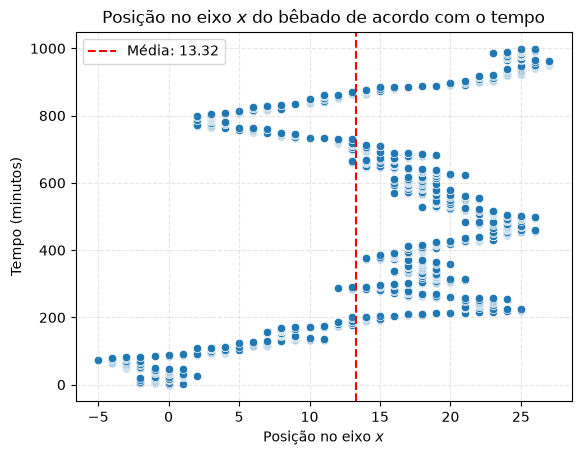

In [59]:
eixo = sns.scatterplot(x=valores_x, y=range(NUM_PASSOS))

eixo.set(
    ylabel="Tempo (minutos)",
    xlabel="Posição no eixo $x$",
    title="Posição no eixo $x$ do bêbado de acordo com o tempo"
);

media_x = np.mean(valores_y)

eixo.grid(True, linestyle="--", alpha=0.3)
plt.axvline(ymin=0, ymax=NUM_PASSOS, x = media_x, color='red', linestyle='--', label=f"Média: {media_x:.2f}");
plt.legend();

> ### 3. Faça um gráfico similar ao anterior, mas para o eixo 𝑦.

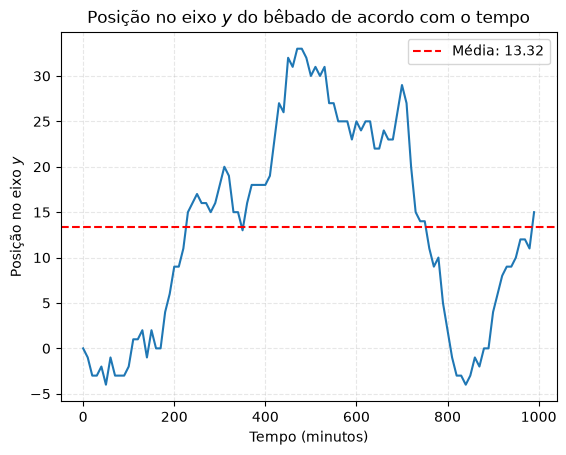

In [58]:
medias = map(np.mean, valores_y[::10])
eixo = sns.lineplot(y=medias, x=range(0, NUM_PASSOS, 10), errorbar=None)
eixo.set(
    ylabel="Posição no eixo $y$",
    xlabel="Tempo (minutos)",
    title="Posição no eixo $y$ do bêbado de acordo com o tempo"
);

media_y = np.mean(valores_y)

plt.axhline(xmin=0, xmax=NUM_PASSOS, y = media_y, color='red', linestyle='--', label=f"Média: {media_y:.2f}")
eixo.grid(True, linestyle="--", alpha=0.3)
plt.legend();

Podemos observar que, embora a probabilidade para "-1" ou "+1" para os eixos seja a exata mesma, a simulação não é eximida de apresentar médias que se distanciem de 0, como poderíamos ter esperado.

> ### 4. Agora, considere que $d(t)$ representa a distância Euclidiana entre o ponto de partida (que é sempre a coordenada (0, 0)) e o ponto de parada após uma caminhada de 𝑡 minutos. Faça um gráfico de $𝐸[𝑑(𝑡)]$ por 𝑡 e discuta o que observou. 



Para isso, vamos criar a função `experimento_caminhada`, a qual simula $N$ caminhadas com $M$ passos cada. Conforme essas simulações são geradas, as posições em cada instante são registradas, de modo que um dicionário carregando as $N$ posições em cada instante $M$ é retornado ao final.

In [11]:
def experimento_caminhada(num_caminhadas, num_passos):
    posicoes_em_cada_minuto = {n: [] for n in range(num_caminhadas)}
    
    for _ in range(num_caminhadas):
        _, val_x, val_y = simula_caminhada(num_passos=num_passos)
        for n, (x, y) in enumerate(zip(val_x, val_y)):
            posicao = (x, y)
            posicoes_em_cada_minuto[n].append(posicao)   

    return posicoes_em_cada_minuto

num_simulacoes = 1_000
posicoes_em_cada_minuto = experimento_caminhada(num_simulacoes, NUM_PASSOS)         

Agora vamos calcular a distância euclidiana de todas as posições de todos os instantes e avaliar a média para obter o valor esperado, conforme $\dfrac{1}{N} \sum_{i=1}^{N} \sqrt{x_i^2 + y_i^2}$ para cada $t$.

In [12]:
def distancia_euclidiana(x, y):
    return np.sqrt(x**2 + y**2)

distancia_media_em_cada_minuto = {n: 0 for n in range(NUM_PASSOS)}

for minuto in posicoes_em_cada_minuto:
    distancias = []

    for posicao in posicoes_em_cada_minuto[minuto]:
        x, y = posicao
        
        distancia = distancia_euclidiana(x, y)
        distancias.append(distancia)

    distancia_media_em_cada_minuto[minuto] = np.mean(distancias)

Agora plotando o valor esperado de acordo com $t$ e comparando com a função $f(t) = \sqrt{t}$:

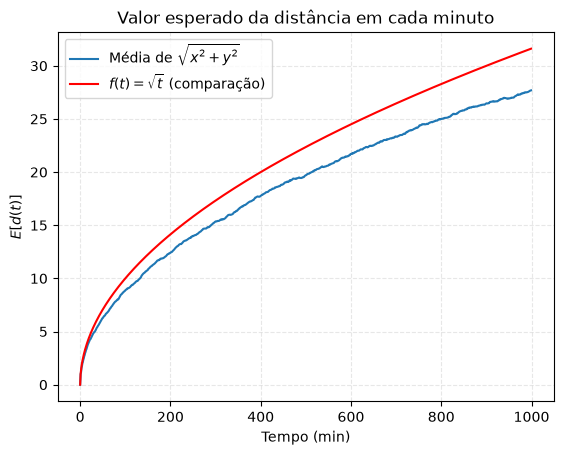

In [57]:
eixo = sns.lineplot(
    x=range(NUM_PASSOS), y=distancia_media_em_cada_minuto.values(),
    label=r"Média de $\sqrt{x^2 + y^2}$"
)

y_raiz = np.sqrt(range(NUM_PASSOS))

sns.lineplot(
    x=range(NUM_PASSOS), y=y_raiz, 
    color='red', ax=eixo, label=r"$f(t) = \sqrt{t}$ (comparação)"
)

eixo.set(
    title="Valor esperado da distância em cada minuto",
    xlabel="Tempo (min)",
    ylabel="$E[d(t)]$"
)

eixo.grid(True, linestyle="--", alpha=0.3)

Podemos inferir por meio desse gráfico que conforme o tempo passa, o bêbado tende a se afastar da origem a uma taxa que se assemelha àquela da função raíz quadrática, divergindo conforme $t$ cresce... mas por que será?

Ocorre que, como é explicado e visualizado em maior detalhe no [item 6](#item-6), as variáveis aleatórias $X$ e $Y$ seguem uma distribuição normal com média em 0 e variância igual de $\dfrac{t}{2}$. Desse modo, pode-se afirmar que $X(t), Y(t) \sim \mathcal{N}\left(0, \, \sigma^2 = \dfrac{t}{2}\right)$. Assim, sendo o vetor bidimensional $V = (X, Y)$ e sua distância euclidiana $D = \sqrt{X^2 + Y^2}$, é possível demonstrar que $D \sim \text{Rayleigh}(\sigma)$ [1]. 

Sim, "Rayleigh" do espalhamento Rayleigh! Sua distribuição é definida pela função de densidade de probabilidade

$$
f(x;\sigma) = \dfrac{x}{\sigma^2} e^{-x^2 / (2\sigma^2)}, x \geq 0
$$

Em que $\sigma$ é o *parâmetro de escala* da distribuição, que corresponde ao desvio padrão comum às suas componentes $X$ e $Y$. Além disso, seu *valor esperado* é dado por 

$$
\text{E}[X] = \sigma\sqrt{\dfrac{\pi}{2}}.
$$

Portanto, o valor esperado para a distância do bêbado à origem em relação ao tempo é calculado como

$$
\text{E}[X] = \sqrt{\dfrac{t}{2}} \cdot \sqrt{\dfrac{\pi}{2}} = \dfrac{\sqrt{\pi\cdot t}}{2} \approx 0.886 \sqrt{t}.
$$

Plotando a função de comparação correta:

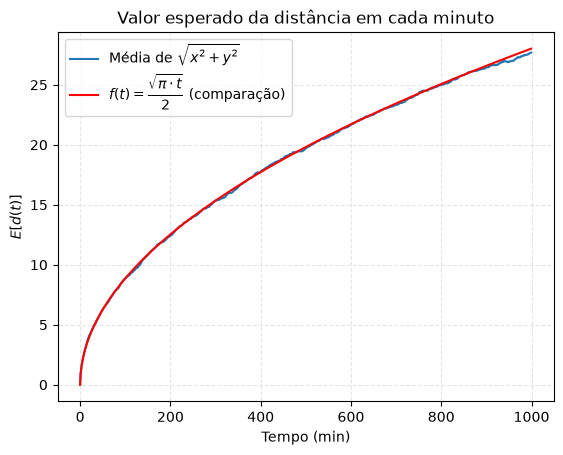

In [55]:
eixo = sns.lineplot(
    x=range(NUM_PASSOS), y=distancia_media_em_cada_minuto.values(),
    label=r"Média de $\sqrt{x^2 + y^2}$"
)

y_raiz = np.sqrt(np.arange(NUM_PASSOS) * np.pi)/2

sns.lineplot(
    x=range(NUM_PASSOS), y=y_raiz, 
    color='red', ax=eixo, label=r"$f(t) = \dfrac{\sqrt{\pi \cdot t}}{2}$ (comparação)"
);

eixo.set(
    title="Valor esperado da distância em cada minuto",
    xlabel="Tempo (min)",
    ylabel="$E[d(t)]$"
)

eixo.grid(True, linestyle="--", alpha=0.3)

## Faça também um gráfico de 𝐸[$𝑑^2$(𝑡)] por 𝑡 e discuta o que observou. 

Vamos obter a média do quadrado da distância de todas as posições em cada instante $t$ a partir do cálculo $\dfrac{1}{N} \sum_{i=1}^{N} x_i^2 + y_i^2$.

In [25]:
soma_media_em_cada_minuto = {n: 0 for n in range(NUM_PASSOS)}

for n, minuto in enumerate(posicoes_em_cada_minuto):
    somas = []
    for posicao in posicoes_em_cada_minuto[minuto]:
        x, y = posicao
        soma = x**2 + y**2
        somas.append(soma)
    soma_media_em_cada_minuto[n] = np.mean(somas)

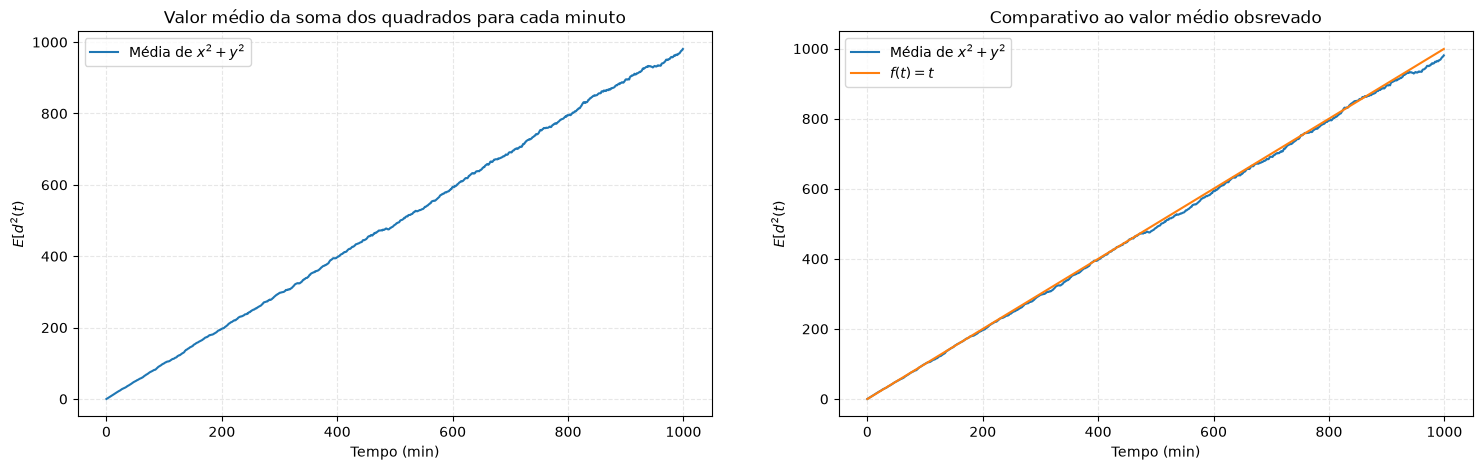

In [69]:
fig, eixos = plt.subplots(1, 2, figsize=(18, 5))

for ax in eixos:
  ax.grid(True, linestyle="--", alpha=0.3)

sns.lineplot(
    x=range(NUM_PASSOS), y=soma_media_em_cada_minuto.values(), 
    label=r"Média de $x^2 + y^2$", ax=eixos[0]
)

eixos[0].set(
    title="Valor médio da soma dos quadrados para cada minuto",
    xlabel="Tempo (min)",
    ylabel="$E[d^2(t)$"
);

sns.lineplot(
    x=range(NUM_PASSOS), y=soma_media_em_cada_minuto.values(), 
    label=r"Média de $x^2 + y^2$", ax=eixos[1]
)

sns.lineplot(
    x=range(NUM_PASSOS), y=range(NUM_PASSOS), 
    label="$f(t) = t$", ax=eixos[1]
);

eixos[1].set(
    title="Comparativo ao valor médio obsrevado",
    ylabel="$E[d^2(t)$",
    xlabel="Tempo (min)",
);

Pode-se notar que há uma correlação muito próxima do valor méido da soma dos quadrados à função identidade, o que pode parecer muito curioso à primeira vista! Vamos analisar a razão disto com base no valor esperado para as componentes $x^2$ e $y^2$ individualmente.

### Analisando $E[x^2(t)]$ e $E[y^2(t)]$

Como foi definido, cada movimento do bêbado é independente e suas orientações possíveis são equiprováveis. Vamos analisar o valor esperado para os eixos:

| Movimento | Vetor `(Δx, Δy)` | Variação em $X^2$ ($\Delta x^2$) | Variação em $Y^2$ ($\Delta y^2$) | Probabilidade |
| --- | --- | --- | --- | --- |
| **Direita** | `(1, 0)` | $(+1)^2 = 1$ | $0$ | $1/4$ |
| **Esquerda** | `(-1, 0)` | $(-1)^2 = 1$ | $0$ | $1/4$ |
| **Cima** | `(0, 1)` | $0$ | $(+1)^2 = 1$ | $1/4$ |
| **Baixo** | `(0, -1)` | $0$ | $(-1)^2 = 1$ | $1/4$ |


Dessa forma, 

$$E[X^2] = \dfrac{1}{4} \cdot 1 + \dfrac{1}{4} \cdot 1 + \dfrac{1}{4} \cdot 0 + \dfrac{1}{4} \cdot 0 = \dfrac{1}{2}$$

E o mesmo vale para $E[Y^2]$:

$$E[Y^2] = \dfrac{1}{4} \cdot 0 + \dfrac{1}{4} \cdot 0 + \dfrac{1}{4} \cdot 1 + \dfrac{1}{4} \cdot 1 = \dfrac{1}{2}$$

Portanto, quando temos $E[d^2(t)]$ como $E[x^2(t) + y^2(t)]$, pela aditividade da esperança, isso equivale a $E[x^2(t)] + E[y^2(t)] = \dfrac{t}{2} + \dfrac{t}{2} = t$. Desse modo, isso explica o comportamento do valor médio observado no gráfico acima.

In [28]:
x2_medio_em_cada_minuto = {n: [] for n in range(1_000)}
y2_medio_em_cada_minuto = {n: [] for n in range(1_000)}

for minuto in posicoes_em_cada_minuto:    
    
    x2 = list(map(lambda x: x[0]**2, posicoes_em_cada_minuto[minuto]))
    y2 = list(map(lambda x: x[1]**2, posicoes_em_cada_minuto[minuto]))

    media_x2 = np.mean(x2)
    media_y2 = np.mean(y2)

    x2_medio_em_cada_minuto[minuto] = media_x2
    y2_medio_em_cada_minuto[minuto] = media_y2

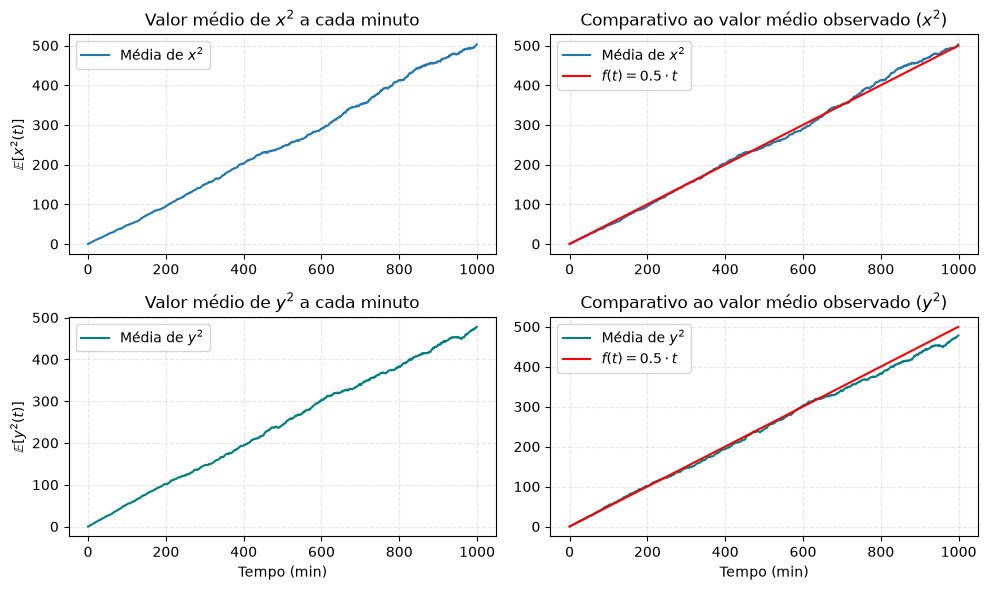

In [67]:
fig, eixos = plt.subplots(2, 2, figsize=(10, 6))

for ax in eixos.flat:
  ax.grid(True, linestyle="--", alpha=0.3)

# ==================== LINHA SUPERIOR: EIXO X ====================
sns.lineplot(
    x=range(NUM_PASSOS),
    y=list(x2_medio_em_cada_minuto.values()),
    label=r"Média de $x^2$",
    ax=eixos[0, 0],
)
eixos[0, 0].set(
    title=r"Valor médio de $x^2$ a cada minuto",
    ylabel=r"$\mathbb{E}[x^2(t)]$",
)

# Subplot (0, 1) - Comparativo X² vs Teoria
sns.lineplot(
    x=range(NUM_PASSOS),
    y=list(x2_medio_em_cada_minuto.values()),
    label=r"Média de $x^2$",
    ax=eixos[0, 1],
)
sns.lineplot(
    x=range(NUM_PASSOS),
    y=0.5 * np.arange(NUM_PASSOS),
    label=r"$f(t) = 0.5 \cdot t$",
    color="red",
    ax=eixos[0, 1],
)
eixos[0, 1].set(
    title=r"Comparativo ao valor médio observado ($x^2$)",
)

# ==================== LINHA INFERIOR: EIXO Y ====================
# Subplot (1, 0) - Média observada de Y²
sns.lineplot(
    x=range(NUM_PASSOS),
    y=list(y2_medio_em_cada_minuto.values()),
    label=r"Média de $y^2$",
    color="teal",
    ax=eixos[1, 0],
)
eixos[1, 0].set(
    title=r"Valor médio de $y^2$ a cada minuto",
    xlabel="Tempo (min)",
    ylabel=r"$\mathbb{E}[y^2(t)]$",
)

# Subplot (1, 1) - Comparativo Y² vs Teoria
sns.lineplot(
    x=range(NUM_PASSOS),
    y=list(y2_medio_em_cada_minuto.values()),
    label=r"Média de $y^2$",
    color="teal",
    ax=eixos[1, 1],
)
sns.lineplot(
    x=range(NUM_PASSOS),
    y=0.5 * np.arange(NUM_PASSOS),
    label=r"$f(t) = 0.5 \cdot t$",
    color="red",
    ax=eixos[1, 1],
)
eixos[1, 1].set(
    title=r"Comparativo ao valor médio observado ($y^2$)",
    xlabel="Tempo (min)"
)

plt.tight_layout()
plt.show()

Temos que o valor esperado do 

### Avaliando $E[y^2(t)]$

In [30]:
y2_medio_em_cada_minuto = {n: [] for n in range(1_000)}

for minuto in posicoes_em_cada_minuto:    
    
    y2 = list(map(lambda x: x[1]**2, posicoes_em_cada_minuto[minuto]))

    media_y2 = np.mean(y2)

    y2_medio_em_cada_minuto[minuto] = media_y2

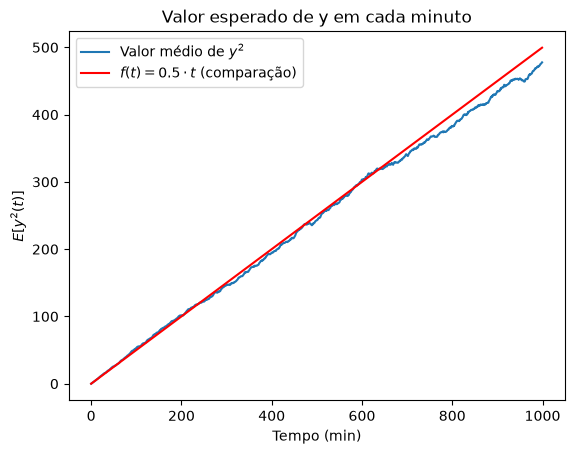

In [31]:
eixo = sns.lineplot(
    x=range(NUM_PASSOS), y=y2_medio_em_cada_minuto.values(),
    label="Valor médio de $y^2$"
)

y_linha = 0.5 * np.arange(1000)

sns.lineplot(
    x=range(NUM_PASSOS), y=y_linha, 
    color='red', ax=eixo, label=r"$f(t) = 0.5 \cdot t$ (comparação)"
);

eixo.set(
    title="Valor esperado de y em cada minuto",
    xlabel="Tempo (min)",
    ylabel="$E[y^2(t)]$"
);

### Comaprando a soma de ambos a $E[d^2(t)]$

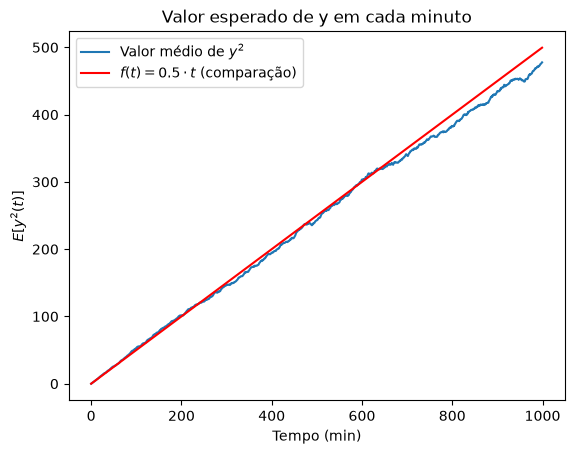

In [ ]:
eixo = sns.lineplot(
    x=range(NUM_PASSOS), y=y2_medio_em_cada_minuto.values(),
    label="Valor médio de $y^2$"
)

y_linha = 0.5 * np.arange(1000)

sns.lineplot(
    x=range(NUM_PASSOS), y=y_linha, 
    color='red', ax=eixo, label=r"$f(t) = 0.5 \cdot t$ (comparação)"
);

eixo.set(
    title="Valor esperado de y em cada minuto",
    xlabel="Tempo (min)",
    ylabel="$E[y^2(t)]$"
);

In [32]:
soma_media_quadrados = {n: 0 for n in range(num_simulacoes)}

for n, (x, y) in enumerate((x2_medio_em_cada_minuto.values(), y2_medio_em_cada_minuto.values())):
    soma_media_quadrados[n] = x + y

ValueError: too many values to unpack (expected 2)

## 6. Considere um valor de 𝑡 fixo (por exemplo, 𝑡 = 500 minutos). Mostre a distribuição dos valores finais de 𝑥 após essa caminhada e relacione o observado com Teorema do Limite Central.

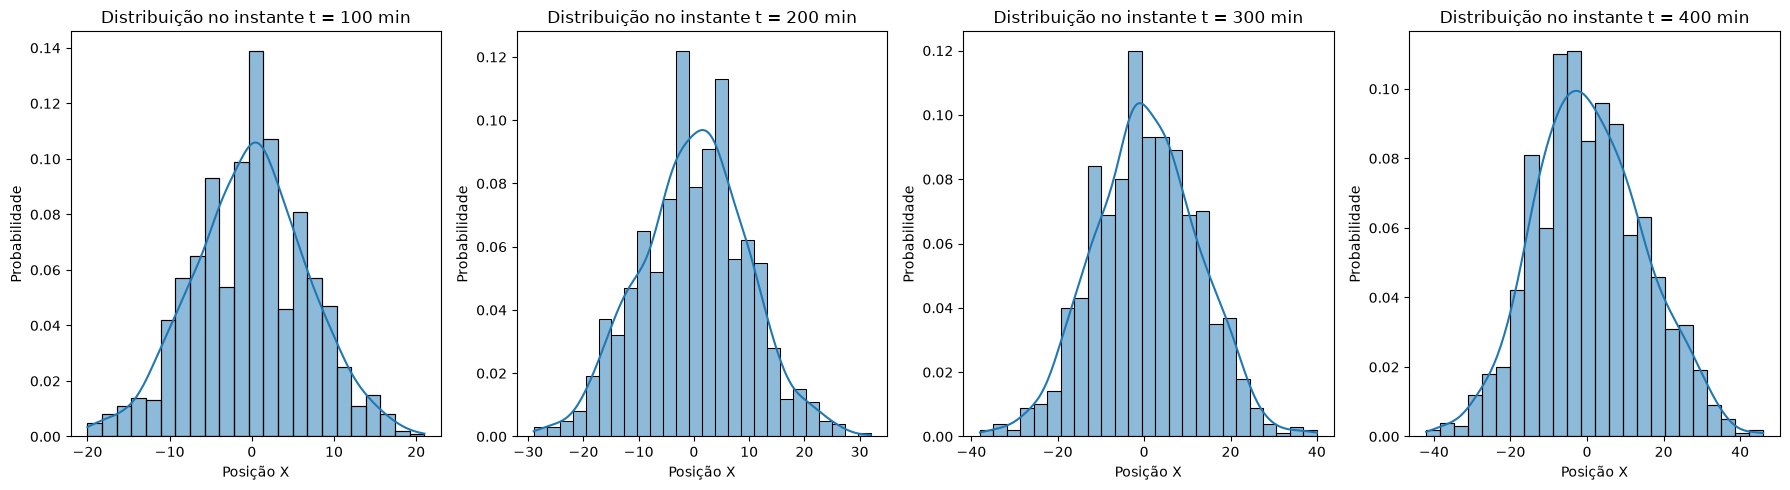

In [116]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, eixos = plt.subplots(1, 4, figsize=(18, 5))

# Use enumerate para obter o índice do gráfico (0, 1, 2) e o valor de i (7, 8, 9)
for idx, i in enumerate(range(4, 8)):
  minuto = i * 100
  posicoes_em_t = posicoes_em_cada_minuto[minuto]

  # Extrai apenas as coordenadas X
  valores_x = [pos[0] for pos in posicoes_em_t]

  # Plota no sub-eixo correto usando sns.histplot com o parâmetro ax
  sns.histplot(x=valores_x, stat="probability", ax=eixos[idx], kde=True)

  # Adiciona títulos e rótulos individuais
  eixos[idx].set_title(f"Distribuição no instante t = {minuto} min")
  eixos[idx].set_xlabel("Posição X")
  eixos[idx].set_ylabel("Probabilidade")

plt.tight_layout()
plt.show()

### Para as posições no eixo Y:

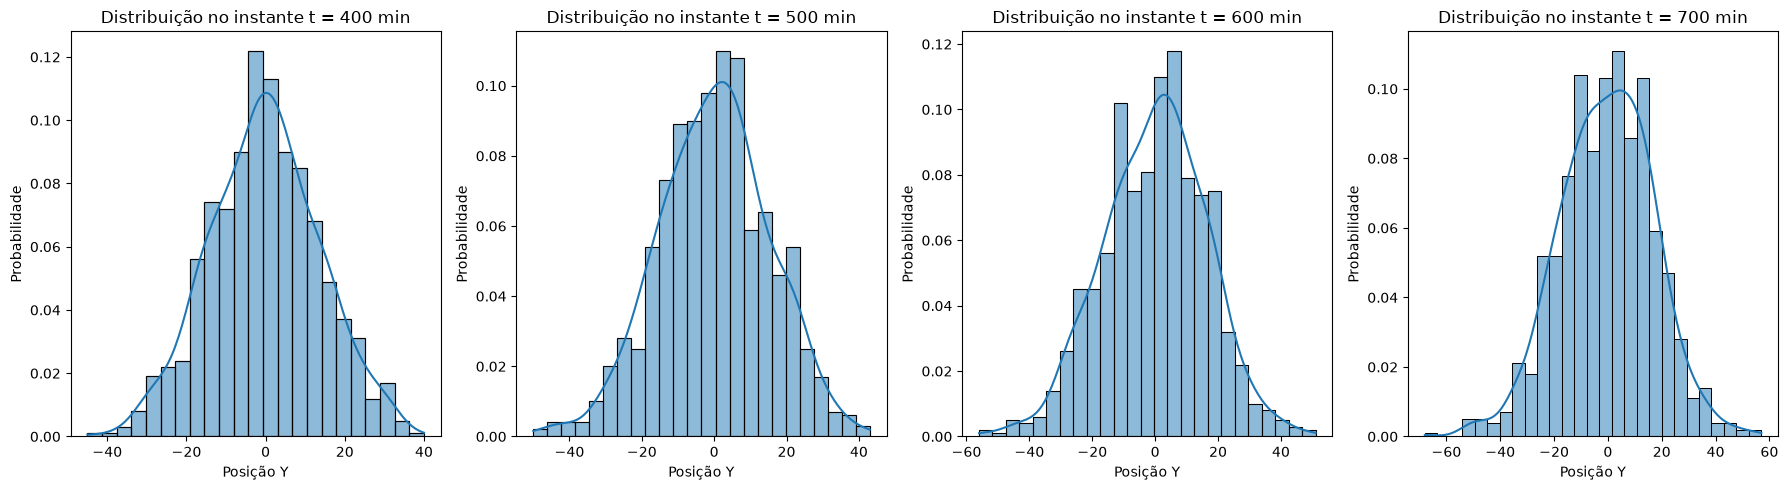

In [118]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, eixos = plt.subplots(1, 4, figsize=(18, 5))

# Use enumerate para obter o índice do gráfico (0, 1, 2) e o valor de i (7, 8, 9)
for idx, i in enumerate(range(4, 8)):
  minuto = i * 100
  posicoes_em_t = posicoes_em_cada_minuto[minuto]

  # Extrai apenas as coordenadas X
  valores_x = [pos[1] for pos in posicoes_em_t]

  # Plota no sub-eixo correto usando sns.histplot com o parâmetro ax
  sns.histplot(x=valores_x, stat="probability", ax=eixos[idx], kde=True)

  # Adiciona títulos e rótulos individuais
  eixos[idx].set_title(f"Distribuição no instante t = {minuto} min")
  eixos[idx].set_xlabel("Posição Y")
  eixos[idx].set_ylabel("Probabilidade")

plt.tight_layout()
plt.show()

Quando nós temos uma variável independente cujos resultados independem entre si, 

In [ ]:
import scipy.stats as stats

NIVEL_CONFIANCA = 0.95
SIGNIFICANCIA = 1 - NIVEL_CONFIANCA

for t in NUM_PASSOS:
    posicoes_t = posicoes_em_cada_minuto[t]
    val_x = [pos[0] for pos in posicoes_t]
    _, pvalor = stats.shapiro(valores_x)
    if pvalor < SIGNIFICANCIA:
        print(f"H0 Rejeitada em t = {t}!")


Tarefas opcionais para quem quiser aprender mais (as respostas não estarão no
gabarito):
• Qual é a probabilidade do bêbado retornar à origem em qualquer momento
após 𝑡 = 0 (isto é, não considerando o instante inicial que o bêbado está na
origem)? Mostrar um gráfico desta probabilidade em função do total de minutos
da caminhada.
• Você pode ver o que acontece ao alterar a probabilidade de dar um passo em
cada direção. Por exemplo, um passo para norte pode ser mais provável do que
um passo para leste. Como isso altera os resultados obtidos?
• Você pode fazer com que o tamanho do passo não seja perfeitamente de 1 metro,
mas sim um passo variável que segue uma distribuição a sua escolha.
• Você pode fazer o piloto espacial embriagado, onde ele pode se mover em 3
dimensões.
• Você pode remover o limite do bêbado de andar apenas em 4 direções. Quem
sabe você poderia adicionar diagonais ou até sortear um ângulo entre 0 e 2π para
o movimento.

## Referências

[1] https://en.wikipedia.org/wiki/Rayleigh_distribution

[2] quarto.wessa.net/rayleigh.html

## Uso de IA neste trabalho

- Busca geral de testes adequados apresentados nos materiais da disciplina.

<div style="width: 100%; text-align: center; margin-bottom: 20px;">
  <img src="../elementos/rodape_branco.png" alt="Rodapé" style="max-width: 100%; height: auto;">
</div>

Monstro: Múmia Fermentada.
Um senhor acabou exagerando e tomou uma ou duas doses a mais do que deveria.
Esse senhor embriagado está andando por um campo plano, infinito e livre de obstáculos.
A cada minuto, ele dá um passo de exatamente 1 metro para norte, sul, leste ou oeste.
É sempre um passo por minuto e sempre um passo em apenas uma direção (todas as
direções têm a mesma probabilidade de serem escolhidas).
Considere que o senhor andante inicia sua trajetória no tempo 𝑡 = 0 minutos na
coordenada (0, 0).
26
Considerando uma caminhada do senhor onde se passaram 1000 minutos, faça os
gráficos abaixo.
1. Faça um gráfico mostrando a trajetória do bebum andante no plano.
2. Faça um gráfico da posição no eixo 𝑥 do andarilho inebriado em função do tempo.
3. Faça um gráfico similar ao anterior, mas para o eixo 𝑦.

